In [1]:
import pandas as pd

In [2]:
# Utility: display a Python list in multiple columns for compact viewing
import math
import numpy as np
from IPython.display import display


def list_to_columns(items, ncols: int = 6, fill_order: str = 'column'):
    # Display items in a DataFrame laid out with ncols columns.
    # fill_order='row':    fill rows left->right
    # fill_order='column': fill columns top->bottom (often more compact)
    items = [str(x) for x in items]
    if not items:
        print('(empty)')
        return
    nrows = math.ceil(len(items) / max(ncols, 1))
    padded = items + [''] * (nrows * ncols - len(items))
    arr = np.array(padded)
    if fill_order == 'row':
        arr = arr.reshape(nrows, ncols)
    else:
        arr = arr.reshape(ncols, nrows).T  # column-wise fill
    df = pd.DataFrame(arr, columns=[f'col{i+1}' for i in range(ncols)])
    try:
        display(df.style.hide(axis='index'))
    except Exception:
        display(df)


# Helper: paginate a DataFrame into a multi-column layout
import math
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

def display_multicol_paginated(df: pd.DataFrame, label_col: str, value_col: str, *, ncols: int = 4, nrows: int = 25, page: int = 1, fmt: str = '{label} — {value:,}'):
    """Show df[label_col,value_col] in a compact grid with pagination.
    - ncols: number of columns in the grid
    - nrows: number of rows per column (items per page = ncols * nrows)
    - page: 1-based page index
    - fmt: string template for each cell
    """
    if df.empty:
        print('(empty)')
        return
    items = [fmt.format(label=str(l), value=int(v)) for l, v in df[[label_col, value_col]].itertuples(index=False)]
    per_page = max(1, ncols * nrows)
    total_pages = max(1, math.ceil(len(items) / per_page))
    page = max(1, min(int(page), total_pages))
    start = (page - 1) * per_page
    end = start + per_page
    subset = items[start:end]

    # pad to complete grid
    padded = subset + [''] * (per_page - len(subset))
    arr = np.array(padded).reshape(nrows, ncols)
    grid = pd.DataFrame(arr, columns=[f'col{i+1}' for i in range(ncols)])
    display(Markdown(f'Page {page} / {total_pages}  •  items {start+1}-{min(end, len(items))} of {len(items)}'))
    try:
        display(grid.style.hide(axis='index'))
    except Exception:
        display(grid)

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_geo_frac_trend_with_delta(
    norm_df: pd.DataFrame,
    pathogen: str,
    *,
    value_col: str = 'geo_frac',
    title: str | None = None,
    figsize=(10, 6),
    color_line: str = 'tab:red',
    color_bar: str = 'tab:blue',
    marker: str = 'o',
    ax=None,
    ax2=None,
    highlight_labels=None,
    highlight_color: str = 'gold',
    highlight_alpha: float = 0.15,
):
    """Plot per-interval median of value_col with its discrete derivative.

    - Left y-axis: line for median value_col (default: geo_frac) per interval.
    - Right y-axis: bar chart for delta (consecutive differences) with y=0 baseline.
    - X ticks: one per interval label in chronological order.

    """
    if norm_df.empty:
        print('norm_df is empty')
        return

    nd = norm_df.copy()
    if 'interval_label' not in nd.columns:
        nd['start_year'] = pd.to_datetime(nd['start_date']).dt.year
        nd['end_year'] = pd.to_datetime(nd['end_date']).dt.year
        nd['interval_label'] = nd['start_year'].astype(str) + '-' + nd['end_year'].astype(str)
    else:
        if 'start_year' not in nd.columns:
            nd['start_year'] = pd.to_datetime(nd['start_date']).dt.year

    pt = nd[nd['pathogen'].str.lower() == str(pathogen).lower()].copy()
    if pt.empty:
        print(f'No rows for pathogen: {pathogen}')
        return

    order = (
        pt.drop_duplicates(['interval_label', 'start_year']).sort_values('start_year')['interval_label'].tolist()
    )

    series = pd.to_numeric(pt[value_col], errors='coerce')
    pt = pt.assign(_val=series)
    trend = pt.groupby('interval_label')['_val'].median().reindex(order)
    trend = trend.fillna(0.0)

    diff = trend.diff().fillna(0.0)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure
    x_positions = list(range(len(trend)))
    ax.set_xticks(x_positions)
    ax.set_xticklabels(list(trend.index), rotation=45, ha='right')

    ax2 = ax.twinx() if ax2 is None else ax2

    # optional background highlights for specified interval labels
    if highlight_labels is not None and len(highlight_labels) > 0:
        try:
            hl_set = {str(x) for x in highlight_labels}
            for xi, lab in enumerate(trend.index):
                if str(lab) in hl_set:
                    ax.axvspan(xi - 0.5, xi + 0.5, color=highlight_color, alpha=highlight_alpha, zorder=0)
        except Exception:
            pass
    ax2.set_zorder(0)
    ax.set_zorder(1)
    try:
        ax.patch.set_alpha(0.0)
    except Exception:
        pass
    ax2.bar(x_positions, diff.values, color=color_bar, alpha=0.6, width=0.6, label='Δ ' + value_col, zorder=1)
    ax2.axhline(0, color=color_bar, linewidth=1, alpha=0.6)
    ax2.set_ylabel('Δ ' + value_col)

    ax.plot(x_positions, trend.values, marker=marker, color=color_line, label=value_col, zorder=3)
    ax.set_xlabel('Interval')
    ax.set_ylabel('Geometric mean of fractions (relative interest)' if value_col == 'geo_frac' else value_col)
    ax.set_title(title or f'Median {value_col} over time — {pathogen}')

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc='upper left')

    try:
        fig.tight_layout()
    except Exception:
        pass
    ax.grid()
    return ax, ax2

---

# Data

In [4]:
amr_df = pd.read_parquet("pmids_results_positive.parquet")
amr_df

,pathogen,antibiotic,start_date,end_date,pmids,count,venue_histogram
0,Abiotrophia defectiva,Cefepime,2015/01/01,2019/12/31,[27216060],1,"{""Antimicrobial agents and chemotherapy"": 1}"
1,Abiotrophia defectiva,Ciprofloxacin,2010/01/01,2014/12/31,[24034902],1,"{""Diagnostic microbiology and infectious disea..."
2,Abiotrophia defectiva,Clindamycin,2000/01/01,2004/12/31,[10681362],1,"{""Antimicrobial agents and chemotherapy"": 1}"
3,Abiotrophia defectiva,Clindamycin,2015/01/01,2019/12/31,[26666926],1,"{""Antimicrobial agents and chemotherapy"": 2}"
4,Abiotrophia defectiva,Daptomycin,2020/01/01,2024/12/31,[34252304],1,"{""Antimicrobial agents and chemotherapy"": 1}"
...,...,...,...,...,...,...,...
14018,Yersinia pseudotuberculosis,Streptomycin,1990/01/01,1994/12/31,"[1454082, 2337369]",2,"{""Molekuliarnaia genetika, mikrobiologiia i vi..."
14019,Yersinia pseudotuberculosis,Streptomycin,2005/01/01,2009/12/31,[16279525],1,"{""Gut"": 1, ""Medycyna doswiadczalna i mikrobiol..."
14020,Yersinia pseudotuberculosis,Sulfafurazole,2015/01/01,2019/12/31,[29691860],1,"{""Australian veterinary journal"": 1}"
14021,Yokenella regensburgei,Amoxicillin,2020/01/01,2024/12/31,[37970085],1,"{""Access microbiology"": 1}"


In [5]:
pathogens = sorted(amr_df['pathogen'].value_counts().index.values)
print(f'{len(pathogens)}')

list_to_columns(pathogens, ncols=10, fill_order='column')

558


col1,col2,col3,col4,col5,col6,col7,col8,col9,col10
Abiotrophia defectiva,Bacteroides uniformis,Chryseobacterium indologenes,Dolosigranulum pigrum,Gordonia terrae,Leuconostoc pseudomesenteroides,Mycobacterium terrae,Peptoniphilus asaccharolyticus,Schaalia meyeri,Streptococcus halichoeri
Achromobacter denitrificans,Bartonella bacilliformis,Citrobacter amalonaticus,Dysgonomonas capnocytophagoides,Granulicatella adiacens,Ligilactobacillus salivarius,Mycobacterium tuberculosis,Peptoniphilus harei,Schaalia odontolytica,Streptococcus iniae
Achromobacter xylosoxidans,Bartonella henselae,Citrobacter braakii,Edwardsiella tarda,Granulicatella elegans,Listeria innocua,Mycobacterium ulcerans,Peptostreptococcus anaerobius,Schaalia radingae,Streptococcus intermedius
Acinetobacter baumannii,Bartonella quintana,Citrobacter freundii,Eggerthella lenta,Haemophilus aegyptius,Listeria ivanovii,Mycobacterium wolinskyi,Phocaeicola vulgatus,Schaalia turicensis,Streptococcus lutetiensis
Acinetobacter bereziniae,Bifidobacterium breve,Citrobacter koseri,Ehrlichia chaffeensis,Haemophilus ducreyi,Listeria monocytogenes,Mycobacterium xenopi,Photobacterium damselae,Serratia ficaria,Streptococcus mitis
Acinetobacter calcoaceticus,Bifidobacterium scardovii,Citrobacter werkmanii,Ehrlichia sennetsu,Haemophilus influenzae,Lysinibacillus fusiformis,Mycoplasmoides genitalium,Photorhabdus luminescens,Serratia fonticola,Streptococcus mutans
Acinetobacter haemolyticus,Bilophila wadsworthia,Clostridioides difficile,Eikenella corrodens,Haemophilus parainfluenzae,Lysinibacillus sphaericus,Mycoplasmoides pneumoniae,Plesiomonas shigelloides,Serratia liquefaciens,Streptococcus oralis
Acinetobacter johnsonii,Blautia producta,Clostridium botulinum,Elizabethkingia anophelis,Hafnia alvei,Mannheimia haemolytica,Mycoplasmopsis fermentans,Pluralibacter gergoviae,Serratia marcescens,Streptococcus parasanguinis
Acinetobacter junii,Bordetella bronchiseptica,Clostridium butyricum,Elizabethkingia meningoseptica,Helcococcus kunzii,Mediterraneibacter gnavus,Myroides odoratimimus,Porphyromonas asaccharolytica,Serratia odorifera,Streptococcus pluranimalium
Acinetobacter lwoffii,Bordetella hinzii,Clostridium innocuum,Elizabethkingia miricola,Helicobacter canis,Metamycoplasma hominis,Myroides odoratus,Porphyromonas endodontalis,Serratia plymuthica,Streptococcus pneumoniae


In [6]:
ab_counts_df = pd.read_parquet("antibiotic_tiab_counts.parquet")
ab_counts_df

,antibiotic,year,count
0,Spectinomycin,1950,0
1,Spectinomycin,1951,0
2,Spectinomycin,1952,0
3,Spectinomycin,1953,0
4,Spectinomycin,1954,0
...,...,...,...
12515,Tetracycline,2021,2192
12516,Tetracycline,2022,2451
12517,Tetracycline,2023,2341
12518,Tetracycline,2024,2574


In [7]:
antibiotics = sorted(ab_counts_df['antibiotic'].value_counts().index.values)
print(f'#antibiotics:{len(antibiotics)}')
list_to_columns(antibiotics, ncols=12, fill_order='column')

#antibiotics:245


col1,col2,col3,col4,col5,col6,col7,col8,col9,col10,col11,col12
Amikacin,Cefaclor,Cefodizime,Ceftezole,Delafloxacin,Fusidic-acid,Loracarbef,Norfloxacin,Pivmecillinam,Solithromycin,Sulfamethoxazole,Telithromycin
Amoxicillin,Cefadroxil,Cefonicid,Ceftibuten,Demeclocycline,Garenoxacin,Lymecycline,Ofloxacin,Plazomicin,Sparfloxacin,Sulfamethoxazole/trimethoprim,Temafloxacin
Amoxicillin/clavulanic-acid,Cefalexin,Cefoperazone,Ceftizoxime,Dibekacin,Gatifloxacin,Mecillinam,Oleandomycin,Polymyxin-B,Spectinomycin,Sulfamethoxypyridazine,Temocillin
Ampicillin,Cefaloridine,Ceforanide,Ceftobiprole-medocaril,Dicloxacillin,Gemifloxacin,Meropenem,Omadacycline,Pristinamycin,Spiramycin,Sulfametomidine,Tetracycline
Ampicillin/sulbactam,Cefalotin,Cefoselis,Ceftolozane/tazobactam,Dirithromycin,Gentamicin,Meropenem/vaborbactam,Oritavancin,Procaine-benzylpenicillin,Streptoduocin,Sulfametoxydiazine,Thiamphenicol
Arbekacin,Cefamandole,Cefotaxime,Ceftriaxone,Doripenem,Grepafloxacin,Metacycline,Ornidazole,Propicillin,Streptomycin,Sulfametrole/trimethoprim,Ticarcillin
Aspoxicillin,Cefapirin,Cefotetan,Cefuroxime,Doxycycline,Hetacillin,Metampicillin,Oxacillin,Prulifloxacin,Sulbactam,Sulfamoxole,Tigecycline
Azidocillin,Cefatrizine,Cefotiam,Chloramphenicol,Enoxacin,Iclaprim,Meticillin,Oxolinic-acid,Ribostamycin,Sulbenicillin,Sulfamoxole/trimethoprim,Tinidazole
Azithromycin,Cefazedone,Cefoxitin,Chlortetracycline,Epicillin,Imipenem/cilastatin,Metronidazole,Oxytetracycline,Rifabutin,Sulfadiazine,Sulfanilamide,Tobramycin
Azlocillin,Cefazolin,Cefozopran,Cinoxacin,Eravacycline,Imipenem/cilastatin/relebactam,Mezlocillin,Panipenem,Rifampicin,Sulfadiazine/tetroxoprim,Sulfaperin,Tosufloxacin


In [8]:
ab_totals = ab_counts_df.groupby('antibiotic', as_index=False)['count'].sum().sort_values('count', ascending=False)

display_multicol_paginated(ab_totals, 'antibiotic', 'count', ncols=8, nrows=35, page=1)

Page 1 / 1  •  items 1-245 of 245

col1,col2,col3,col4,col5,col6,col7,col8
"Tetracycline — 44,743","Vancomycin — 41,981","Ciprofloxacin — 39,393","Gentamicin — 31,419","Ampicillin — 30,387","Chloramphenicol — 27,289","Erythromycin — 25,057","Amoxicillin — 23,759"
"Trimethoprim — 23,308","Rifampicin — 22,319","Metronidazole — 20,853","Doxycycline — 20,759","Sulfamethoxazole — 20,637","Ceftriaxone — 16,773","Streptomycin — 15,958","Sulfamethoxazole/trimethoprim — 15,279"
"Azithromycin — 15,015","Clindamycin — 14,500","Ceftazidime — 14,146","Amikacin — 13,738","Meropenem — 13,463","Levofloxacin — 13,062","Clarithromycin — 12,669","Colistin — 12,343"
"Cefotaxime — 11,098","Piperacillin — 10,972","Kanamycin — 10,556","Linezolid — 10,084","Minocycline — 9,837","Neomycin — 9,686","Tazobactam — 8,939","Ofloxacin — 8,867"
"Tobramycin — 8,818","Piperacillin/tazobactam — 7,494","Moxifloxacin — 7,491","Polymyxin-B — 7,350","Norfloxacin — 6,786","Oxytetracycline — 6,468","Tigecycline — 6,264","Cefazolin — 6,255"
"Oxacillin — 5,980","Cefoxitin — 5,902","Cefuroxime — 5,719","Cefepime — 5,672","Amoxicillin/clavulanic-acid — 5,095","Sulbactam — 5,071","Fosfomycin — 5,050","Daptomycin — 4,761"
"Teicoplanin — 4,724","Nitrofurantoin — 4,723","Aztreonam — 4,550","Sulfadiazine — 4,472","Cefoperazone — 3,311","Ampicillin/sulbactam — 2,981","Lincomycin — 2,846","Chlortetracycline — 2,842"
"Ertapenem — 2,737","Spectinomycin — 2,732","Benzylpenicillin — 2,647","Ceftazidime/avibactam — 2,561","Cefixime — 2,505","Carbenicillin — 2,256","Fusidic-acid — 2,184","Ticarcillin — 2,158"
"Rifaximin — 2,103","Cloxacillin — 2,096","Gatifloxacin — 1,995","Meticillin — 1,972","Netilmicin — 1,896","Cefaclor — 1,866","Imipenem/cilastatin — 1,747","Roxithromycin — 1,714"
"Rifabutin — 1,705","Rifamycin — 1,676","Pefloxacin — 1,456","Tinidazole — 1,426","Cefamandole — 1,351","Sparfloxacin — 1,317","Spiramycin — 1,273","Cefiderocol — 1,254"


In [9]:
pa_counts_df = pd.read_parquet("pathogen_tiab_counts.parquet")
pa_counts_df

,pathogen,year,count
0,Abiotrophia defectiva,1950,0
1,Abiotrophia defectiva,1951,0
2,Abiotrophia defectiva,1952,0
3,Abiotrophia defectiva,1953,0
4,Abiotrophia defectiva,1954,0
...,...,...,...
39627,Yokenella regensburgei,2021,3
39628,Yokenella regensburgei,2022,2
39629,Yokenella regensburgei,2023,5
39630,Yokenella regensburgei,2024,5


In [10]:
pa_totals = pa_counts_df.groupby('pathogen', as_index=False)['count'].sum().sort_values('count', ascending=False)
display_multicol_paginated(pa_totals, 'pathogen', 'count', ncols=7, nrows=35, page=1)

Page 1 / 4  •  items 1-245 of 773

col1,col2,col3,col4,col5,col6,col7
"Escherichia coli — 331,237","Staphylococcus aureus — 153,699","Pseudomonas aeruginosa — 83,252","Mycobacterium tuberculosis — 68,215","Helicobacter pylori — 53,457","Salmonella enterica — 53,279","Klebsiella pneumoniae — 36,762"
"Streptococcus pneumoniae — 31,629","Listeria monocytogenes — 24,119","Clostridioides difficile — 22,559","Haemophilus influenzae — 20,692","Enterococcus faecalis — 19,056","Acinetobacter baumannii — 17,195","Chlamydia trachomatis — 16,550"
"Staphylococcus epidermidis — 14,458","Streptococcus mutans — 13,035","Neisseria gonorrhoeae — 12,330","Porphyromonas gingivalis — 12,253","Mycobacterium avium — 12,233","Vibrio cholerae — 11,687","Bacillus cereus — 11,545"
"Borrelia burgdorferi — 10,584","Streptococcus pyogenes — 10,382","Campylobacter jejuni — 10,320","Neisseria meningitidis — 9,537","Enterococcus faecium — 9,449","Pseudomonas putida — 8,565","Clostridium perfringens — 8,497"
"Mycoplasmoides pneumoniae — 7,847","Lactococcus lactis — 7,553","Serratia marcescens — 7,317","Brucella melitensis — 7,197","Legionella pneumophila — 7,127","Proteus mirabilis — 6,615","Enterobacter cloacae — 6,563"
"Pseudomonas fluorescens — 6,345","Bordetella pertussis — 6,165","Aeromonas hydrophila — 6,003","Yersinia enterocolitica — 5,970","Bacteroides fragilis — 5,903","Bacillus anthracis — 5,681","Vibrio parahaemolyticus — 5,645"
"Cutibacterium acnes — 5,392","Treponema pallidum — 5,389","Lacticaseibacillus rhamnosus — 5,377","Streptococcus agalactiae — 5,365","Mycobacterium smegmatis — 5,123","Chlamydia pneumoniae — 5,084","Aggregatibacter actinomycetemcomitans — 5,044"
"Fusobacterium nucleatum — 5,036","Mycobacterium leprae — 4,859","Coxiella burnetii — 4,796","Stenotrophomonas maltophilia — 4,719","Pasteurella multocida — 4,658","Burkholderia cepacia — 4,397","Yersinia pestis — 4,284"
"Moraxella catarrhalis — 4,247","Shigella flexneri — 4,189","Bacillus licheniformis — 3,844","Clostridium botulinum — 3,825","Burkholderia pseudomallei — 3,818","Francisella tularensis — 3,668","Mycobacterium abscessus — 3,367"
"Priestia megaterium — 3,047","Micrococcus luteus — 2,971","Anaplasma phagocytophilum — 2,932","Klebsiella aerogenes — 2,861","Citrobacter freundii — 2,690","Streptococcus suis — 2,660","Streptococcus sanguinis — 2,651"


---

# Normalisation Concepts

This notebook adjusts AMR-positive counts by background publication volume to make trends comparable across time and topics.

## Inputs
- `amr_df`: rows per (pathogen, antibiotic, start_date, end_date, count) where `count` is the number of abstracts that explicitly claim resistance for that pair in the interval.
- `pa_counts_df` (pathogen-year): yearly number of PubMed papers mentioning each pathogen (Title/Abstract).
- `ab_counts_df` (antibiotic-year): yearly number of PubMed papers mentioning each antibiotic (Title/Abstract).

## Background volumes (per interval)
For each row in `amr_df`, we sum yearly counts inside the interval to get:
- `bg_pathogen_n`: total pathogen papers in the interval
- `bg_antibiotic_n`: total antibiotic papers in the interval

## Fraction-based indicators
We compute share-of-background metrics with Laplace smoothing (α):
- `frac_among_pathogen = (count + α) / (bg_pathogen_n + α)`
- `frac_among_antibiotic = (count + α) / (bg_antibiotic_n + α)`
- `geo_frac = sqrt(frac_among_pathogen * frac_among_antibiotic)` — a symmetric summary indicating relative interest for the pair in that interval.

## Expected counts via product of marginals (within-pair)
Within each (pathogen, antibiotic) pair, we distribute the pair’s total observed positives across its intervals according to background proportions:
1) Compute interval probabilities with smoothing:
   - `p_path_int = bg_pathogen_n_int / sum(bg_pathogen_n over intervals)`
   - `p_ab_int = bg_antibiotic_n_int / sum(bg_antibiotic_n over intervals)`
2) Independence proxy for interval emphasis: `q_int = p_path_int * p_ab_int`
3) Normalise so expectations sum to the pair’s observed total: `expected_bg_int = pair_total * (q_int / sum(q_int))`

Residual diagnostics:
- `resid_log_bg = log1p(observed) - log1p(expected_bg)` — log-space residual (robust on sparse data)
- `z_bg = (observed - expected_bg) / sqrt(expected_bg)` — Poisson-style z-score

### Explanation

Goal: For a specific (pathogen, antibiotic) pair, estimate how its total positives should spread across intervals if the pair followed broad background tendencies of that pathogen and that antibiotic. This gives a neutral “expected” profile per interval that we can compare the observed profile against.

Step 1 — Background interval probabilities with smoothing:
Compute two marginal distributions over intervals: one from all samples of the pathogen (regardless of antibiotic), and one from all samples of the antibiotic (regardless of pathogen).

Pathogen marginal: p_path_int = bg_pathogen_n_int / sum(bg_pathogen_n over intervals)

Antibiotic marginal: p_ab_int = bg_antibiotic_n_int / sum(bg_antibiotic_n over intervals)

To avoid zero probabilities in sparse bins, apply light smoothing such as a pseudocount: e.g., replace counts with bg_*_n_int + α and denominators with sum(bg_*_n) + α * (#intervals). This stabilizes probabilities, especially for rare intervals.

Step 2 — Independence proxy (product of marginals):

Form an interval weight by multiplying the two marginals: q_int = p_path_int * p_ab_int.

Intuition: intervals favored by both the pathogen and the antibiotic receive higher weight; intervals disfavored by either get down-weighted. This is a simple “no interaction” baseline (like a Naive Bayes-style factorization). It is not asserting true independence, only providing a neutral reference that blends both backgrounds.

Step 3 — Scale to match the pair’s total:

Convert weights into expected counts that sum to the pair’s observed total:

expected_bg_int = pair_total * (q_int / sum(q_int)).

This distributes the pair’s total across intervals proportionally to q_int, ensuring the expectations are on the same scale as the observed counts for that pair.

Properties:

Preserves the pair total (expectations sum to pair_total).
Yields nonzero expectations even in sparse intervals (with smoothing).
Emphasizes intervals supported by both backgrounds, providing a neutral baseline for residuals.
Caveats:

If true pathogen–antibiotic interactions shift interval preference, the product-of-marginals baseline can misestimate expectations.
With very small background totals, smoothed probabilities can still be noisy; consider stronger smoothing or pooling.
If desired, you can tune influence by exponents (e.g., q_int = p_path_int^w * p_ab_int^(1-w)) or by mixing with a uniform prior for additional stability.
Tiny example:
Suppose pair_total = 100. If p_path = [0.6, 0.4] and p_ab = [0.5, 0.5], then q = [0.3, 0.2], normalized to [0.6, 0.4], giving expected = [60, 40].
If instead p_ab = [0.2, 0.8], then q = [0.12, 0.32], normalized to [0.273, 0.727], giving expected = [27.3, 72.7].

resid_log_bg = log1p(observed) - log1p(expected_bg):
This is the difference of the log-transformed counts, using log1p so zeros and small counts are handled gracefully. Because log differences approximate a log fold-change, this residual tells you how much larger or smaller the observed count is than expected on a multiplicative scale: 0 means they match, ~0.69 ≈ log(2) suggests about 2× higher than expected, and −0.69 suggests about half of expected. The log transform compresses large values and reduces the influence of extreme counts, making the metric more robust when data are sparse and skewed. It also avoids infinite values at zero (thanks to the +1), which is common in sparse matrices. Note that it’s an effect-size style residual, not variance-standardized, so it’s great for visualization and comparing enrichment/depletion but not for direct p-values.

z_bg = (observed - expected_bg) / sqrt(expected_bg):
This is a Poisson-style z-score that measures how many standard deviations the observed count is from the expected, assuming Poisson variance equals the mean. Values near 0 indicate agreement with expectation; +2 means about two SDs above expected (unusual but not extreme), and +4 is very unlikely under the Poisson model. Because it standardizes by the expected variability, it’s useful for significance-style diagnostics and can be mapped to p-values if the Poisson assumption holds. It’s sensitive when expected counts are large (small relative deviations can yield meaningful z’s) and can be unstable when expected counts are very small. If overdispersion is present (variance > mean), this z-score can overstate significance, in which case a quasi-Poisson/negative binomial model or an adjusted variance may be more appropriate.

## Interpretation
- Rising `geo_frac` or positive `resid_log_bg/z_bg` suggests the pair gets more AMR-positive mentions than expected given overall attention to the pathogen and antibiotic in that period.
- Negative values indicate lower-than-expected interest.

## Practical notes
- Smoothing (`α`, default 1.0) stabilises fractions when intervals are sparse; increase if you see volatility.
- Ensure yearly backgrounds (`pa_counts_df`, `ab_counts_df`) were collected with comparable TIAB query logic to avoid mismatch.
- Interval length differences are handled by summing yearly counts across each interval.

In [11]:
from amr.normalisation import normalise_by_background, BackgroundNormaliseConfig
from amr.visualization import plot_heatmap_for_pathogen_debiased
import os

In [12]:
# Compute background-normalised AMR metrics
cfg = BackgroundNormaliseConfig(alpha=1.0)
norm_df = normalise_by_background(
    amr_df,
    pathogen_year_df=pa_counts_df,
    antibiotic_year_df=ab_counts_df,
    cfg=cfg,
)
# Persist for reuse if desired
try:
    norm_df.to_parquet("amr_df_normalised.parquet", index=False)
except Exception as e:
    print("Warning: could not save amr_df_normalised.parquet:", e)

norm_df.head(20)

,pathogen,antibiotic,start_date,end_date,pmids,count,venue_histogram,start_year,end_year,bg_pathogen_n,bg_antibiotic_n,frac_among_pathogen,frac_among_antibiotic,geo_frac,expected_bg,resid_log_bg,z_bg
0,Abiotrophia defectiva,Cefepime,2015/01/01,2019/12/31,[27216060],1,"{""Antimicrobial agents and chemotherapy"": 1}",2015,2019,6,202,0.285714,0.009852,0.053056,1.000000,5.000000e-10,1.000000e-09
1,Abiotrophia defectiva,Ciprofloxacin,2010/01/01,2014/12/31,[24034902],1,"{""Diagnostic microbiology and infectious disea...",2010,2014,17,200,0.111111,0.009950,0.033250,1.000000,5.000000e-10,1.000000e-09
2,Abiotrophia defectiva,Clindamycin,2000/01/01,2004/12/31,[10681362],1,"{""Antimicrobial agents and chemotherapy"": 1}",2000,2004,8,229,0.222222,0.008696,0.043959,1.210172,-9.992337e-02,-1.910523e-01
3,Abiotrophia defectiva,Clindamycin,2015/01/01,2019/12/31,[26666926],1,"{""Antimicrobial agents and chemotherapy"": 2}",2015,2019,6,192,0.285714,0.010363,0.054413,0.789828,1.110279e-01,2.364883e-01
4,Abiotrophia defectiva,Daptomycin,2020/01/01,2024/12/31,[34252304],1,"{""Antimicrobial agents and chemotherapy"": 1}",2020,2024,8,252,0.222222,0.007905,0.041913,1.000000,5.000000e-10,1.000000e-09
5,Abiotrophia defectiva,Erythromycin,2000/01/01,2004/12/31,[10681362],1,"{""Antimicrobial agents and chemotherapy"": 1}",2000,2004,9,996,0.200000,0.002006,0.020030,1.131155,-6.351690e-02,-1.233172e-01
6,Abiotrophia defectiva,Erythromycin,2015/01/01,2019/12/31,[26666926],1,"{""Antimicrobial agents and chemotherapy"": 2}",2015,2019,6,1093,0.285714,0.001828,0.022855,0.868845,6.782658e-02,1.407063e-01
7,Abiotrophia defectiva,Levofloxacin,2015/01/01,2019/12/31,[26666926],1,"{""Antimicrobial agents and chemotherapy"": 2}",2015,2019,3,1165,0.500000,0.001715,0.029285,1.000000,5.000000e-10,1.000000e-09
8,Achromobacter denitrificans,Amikacin,1985/01/01,1989/12/31,[3163242],1,"{""Antimicrobial agents and chemotherapy"": 1}",1985,1989,4,1209,0.400000,0.001653,0.025713,1.590849,-2.588386e-01,-4.684489e-01
9,Achromobacter denitrificans,Amikacin,2005/01/01,2009/12/31,[19795625],1,"{""Mikrobiyoloji bulteni"": 1}",2005,2009,2,1292,0.666667,0.001547,0.032112,1.019984,-9.942519e-03,-1.978748e-02


In [13]:
# Optional class mapping for nicer heatmap labels
class_df = None
for path in ("antibiotic_list2.xlsx",):
    if os.path.exists(path):
        try:
            class_df = pd.read_excel(path)
            break
        except Exception as e:
            print(f"Failed to read {path}:", e)
            class_df = None
            
print("Using class_df:", bool(class_df is not None))

Using class_df: True


In [14]:
pathogen_to_plot = "Mycobacterium tuberculosis"

In [15]:
pathogen_to_plot = "Neisseria gonorrhoeae"
antibiotic = 'Thiamphenicol'
date = '2000/01/01'

In [16]:
from amr.visualization import build_pubmed_links_html
from IPython.display import HTML
html = build_pubmed_links_html(amr_df, pathogen_to_plot, antibiotic, date)
HTML(html)

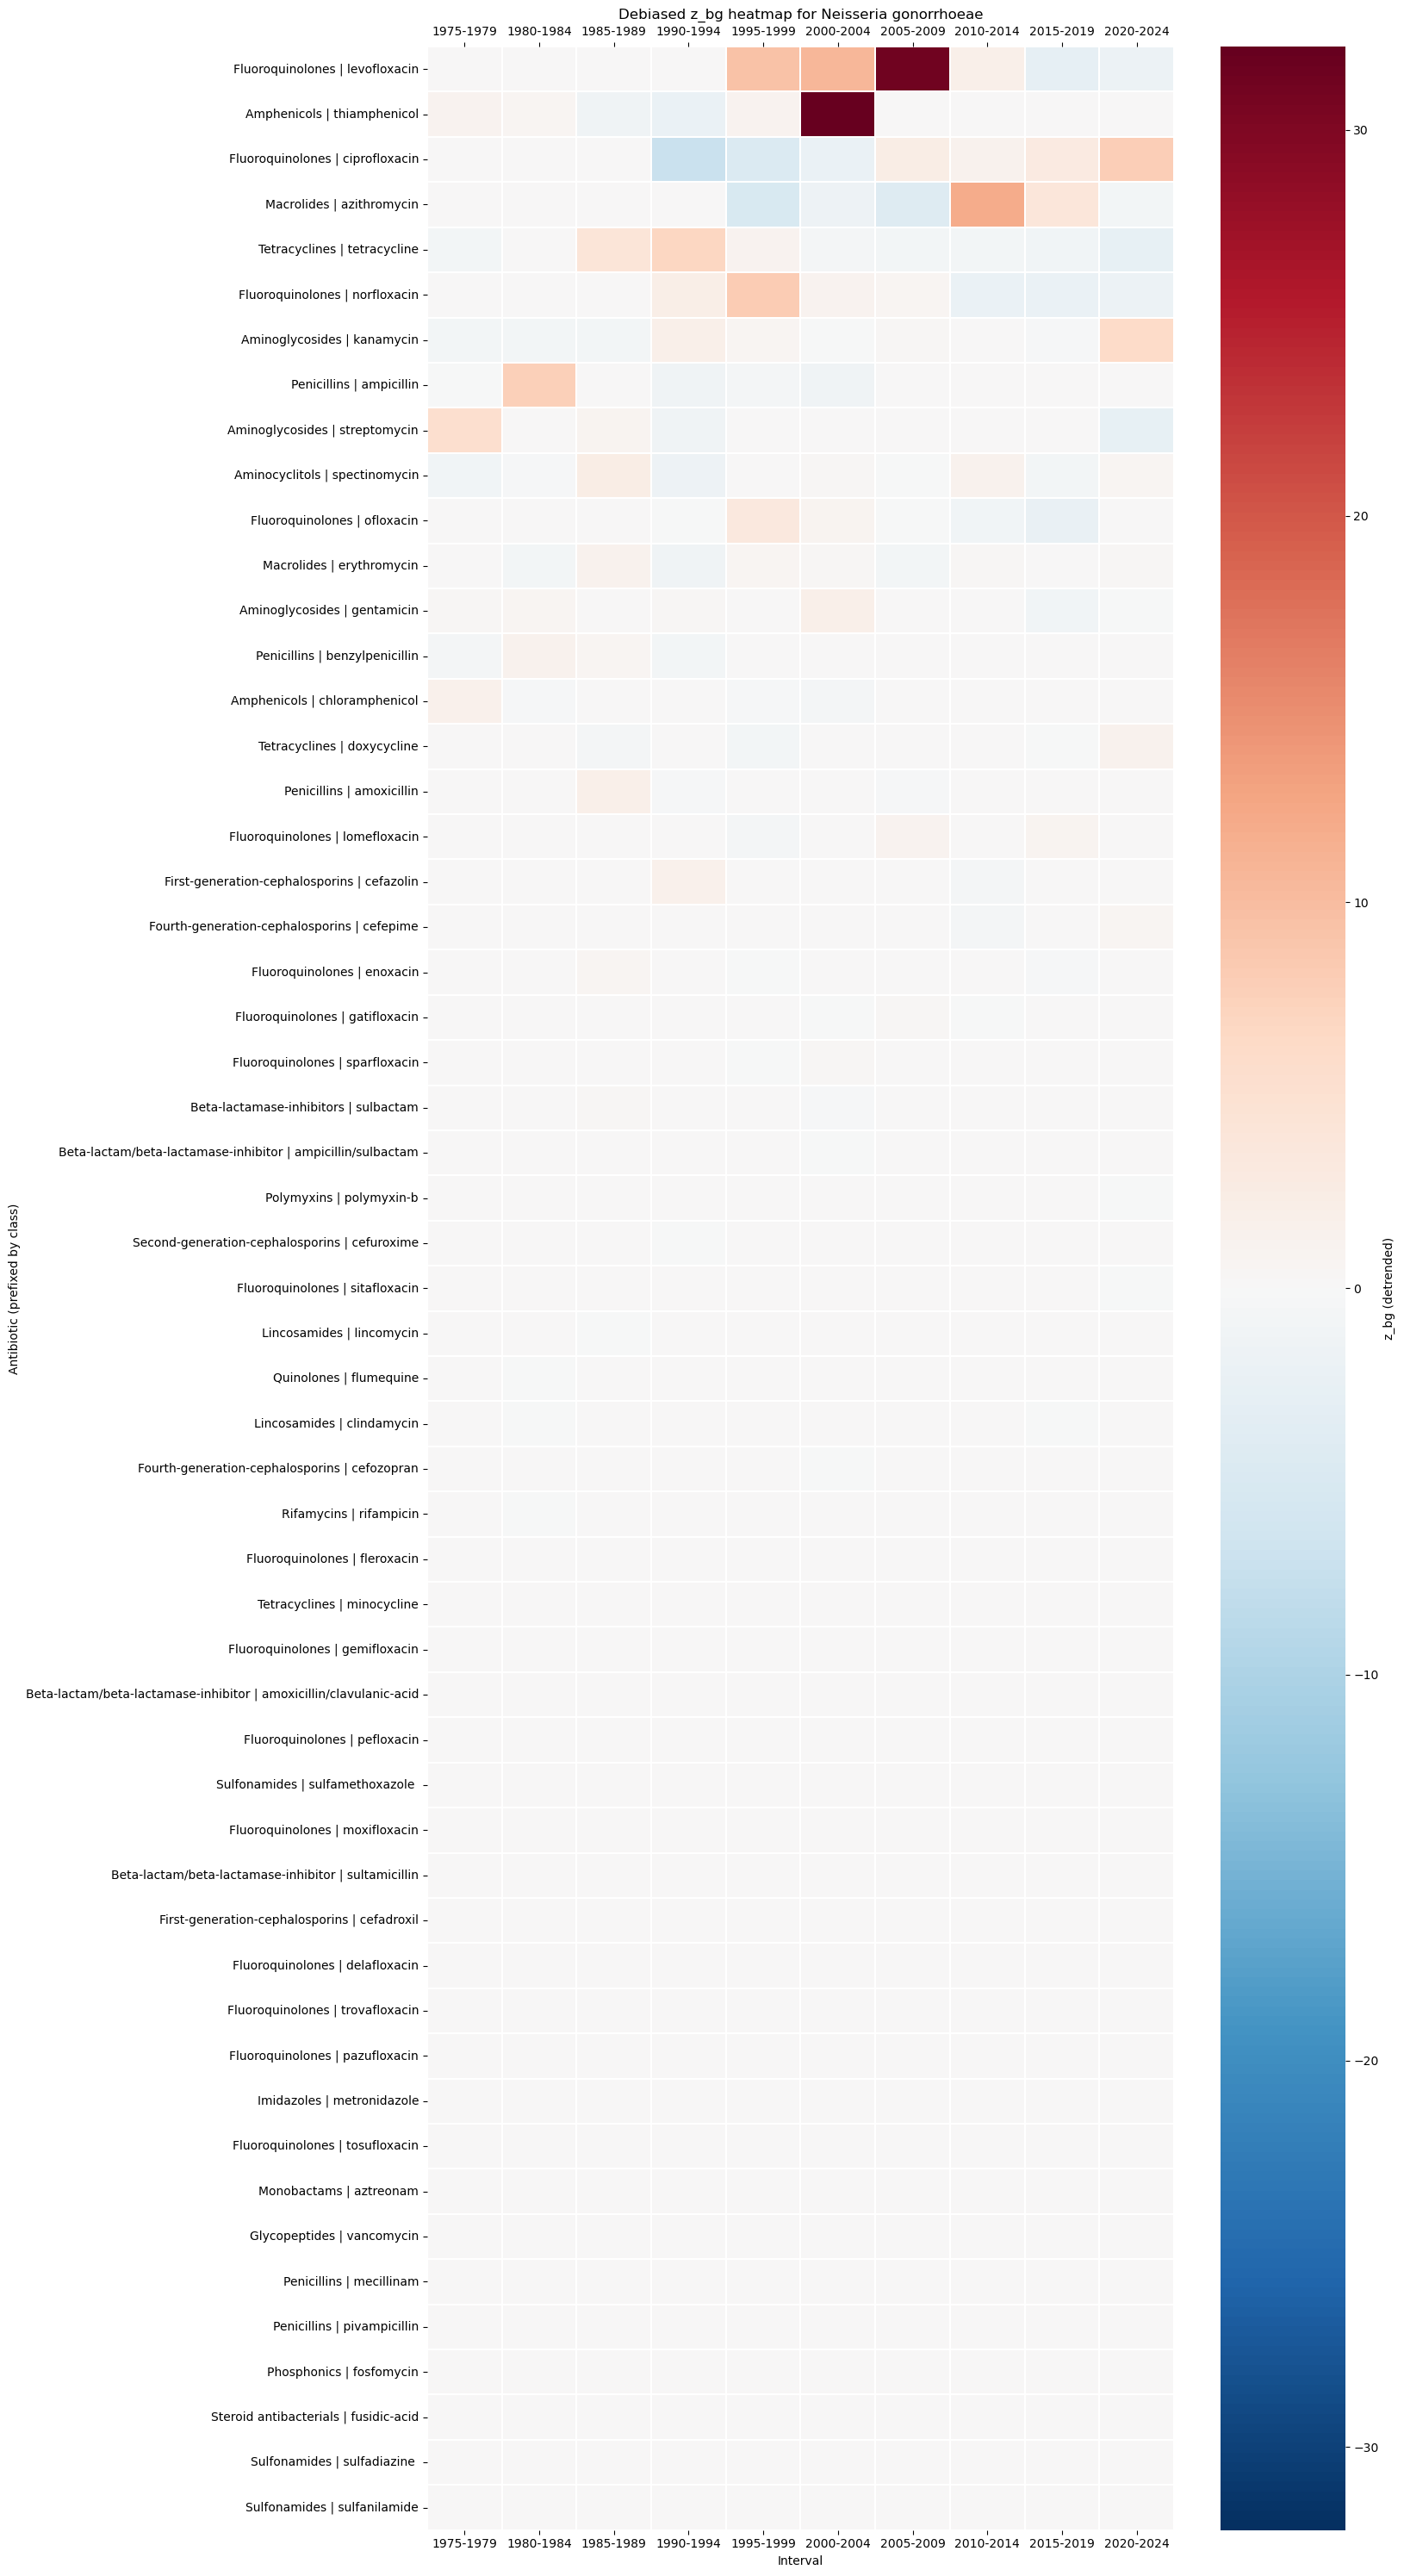

In [17]:
plot_heatmap_for_pathogen_debiased(
    norm_df,
    pathogen=pathogen_to_plot,
    class_df=class_df,
    value="z_bg",  # "resid_log_bg" or "z_bg"
    figsize=(16,30),
)

Read the left panel (geo_frac) as a multiplicative effect-size: the red line is the median relative interest of antibiotic–pathogen pairs for this pathogen in each interval (higher means stronger enrichment), and the blue bars (Δ) show how much that median changed from the previous interval. The right panel (z_bg) is a significance-style view: the green line is the median Poisson z-score comparing observed to expected counts (0 ≈ as expected; positive = above; negative = below), and purple bars show its interval-to-interval change. Because z_bg standardizes by the expected variability, it can move toward or below zero even when geo_frac is steady or rising—especially if background expectations increased or sample sizes changed. In periods like 1995–1999, a jump in expected counts without a matching rise in observed counts pushes z_bg negative, while geo_frac may look flat or only modestly higher because it’s proportion-based and compressed. Use geo_frac to judge practical enrichment trends and z_bg to gauge how surprising they are under a Poisson baseline; when they diverge, suspect shifts in expected counts, small denominators, or composition changes in which pairs contribute to the medians.

/tmp/ipykernel_3515434/2673324170.py:95: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


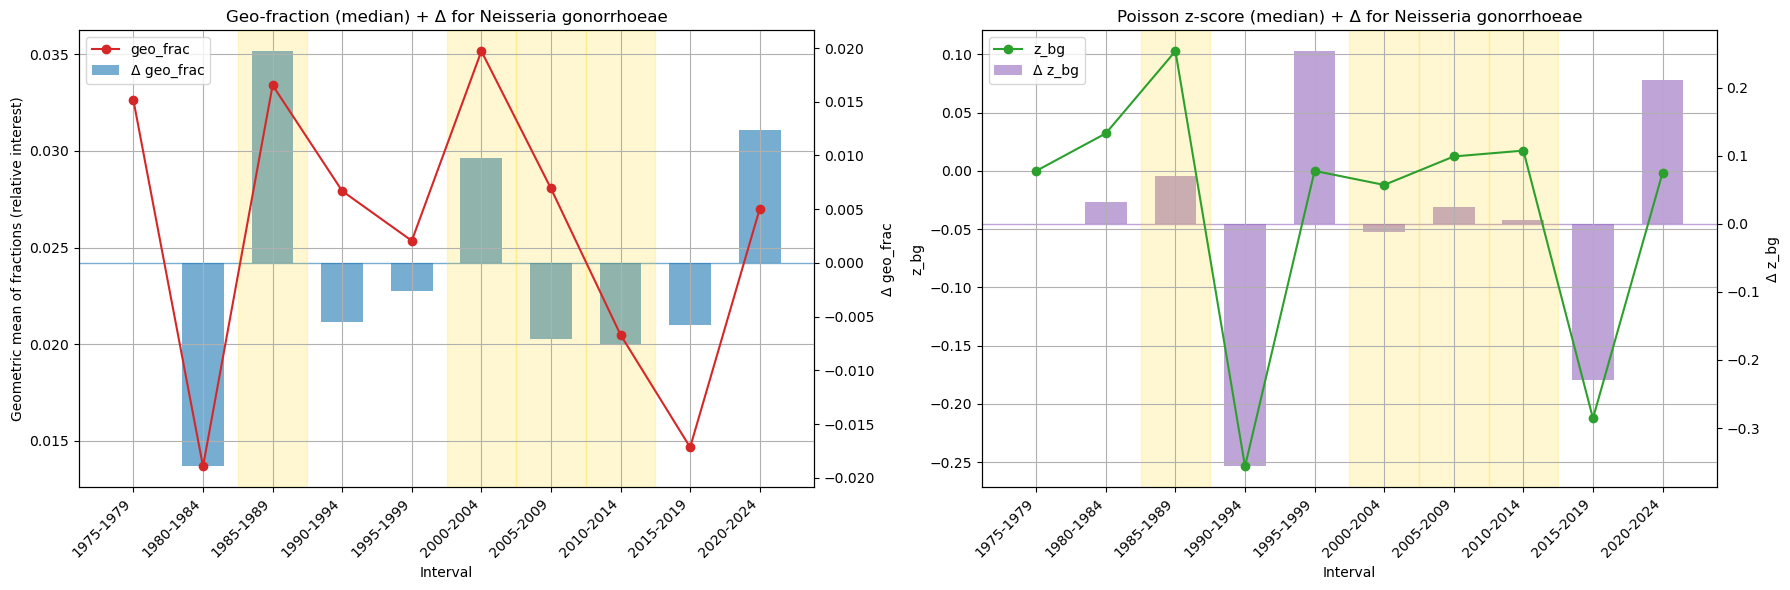

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Build highlight labels: prefer highlight_intervals() if available; otherwise use a lightweight gate
def _interval_labels(df: pd.DataFrame) -> pd.DataFrame:
    if 'interval_label' in df.columns:
        return df
    nd = df.copy()
    nd['start_year'] = pd.to_datetime(nd['start_date']).dt.year
    nd['end_year'] = pd.to_datetime(nd['end_date']).dt.year
    nd['interval_label'] = nd['start_year'].astype(str) + '-' + nd['end_year'].astype(str)
    return nd

def _simple_highlights(df: pd.DataFrame, pathogen: str, *, alpha=0.05, min_pairs=5, min_exp_sum=20, tau_geo=0.03, min_ratio=1.2):
    nd = _interval_labels(df)
    pt = nd[nd['pathogen'].str.lower() == str(pathogen).lower()].copy()
    if pt.empty:
        return []
    g = (pt.groupby('interval_label')
           .agg(
               n_pairs=('antibiotic', 'nunique'),
               obs_sum=('count', 'sum'),
               exp_sum=('expected_bg', 'sum'),
               obs_median=('count', 'median'),
               exp_median=('expected_bg', 'median'),
               geo_median=('geo_frac', 'median'),
               z_median=('z_bg', 'median'),
           )
           .sort_index())
    g = g.assign(sum_ratio=g['obs_sum'] / g['exp_sum'].replace(0, np.nan),
                 med_ratio=g['obs_median'] / g['exp_median'].replace(0, np.nan))
    # crude interval z combine (unweighted Stouffer) using available pair z's
    # rebuild per-interval arrays
    zmap = (nd[nd['pathogen'].str.lower() == str(pathogen).lower()]
              .groupby('interval_label')['z_bg']
              .apply(lambda s: pd.to_numeric(s, errors='coerce').dropna().values))
    def sig_ok(lab):
        arr = zmap.get(lab, np.array([]))
        if arr.size == 0:
            return False
        Z = arr.mean() * np.sqrt(arr.size)
        p = 2 * norm.sf(abs(Z))
        return (Z > 0) and (p <= alpha)
    mask = (g['n_pairs'] >= min_pairs) & (g['exp_sum'] >= min_exp_sum) & \
           ((g['geo_median'] >= tau_geo) | (g['sum_ratio'] >= min_ratio) | (g['med_ratio'] >= min_ratio)) & \
           g.index.to_series().apply(sig_ok)
    return g.index[mask].tolist()

try:
    # If earlier cell defined highlight_intervals, use it
    hl_tbl = highlight_intervals(norm_df, pathogen_to_plot, alpha=0.05, min_pairs=5, min_exp_sum=20,
                                 tau_geo=0.03, min_sum_ratio=1.2, min_prop_sig=0.3)
    highlight_labels = hl_tbl.index[hl_tbl['highlight']].tolist()
except Exception:
    highlight_labels = _simple_highlights(norm_df, pathogen_to_plot)

fig, axs = plt.subplots(1, 2, figsize=(18, 6), constrained_layout=True)

plot_geo_frac_trend_with_delta(
    norm_df, pathogen_to_plot, value_col='geo_frac',
    title=f'Geo-fraction (median) + Δ for {pathogen_to_plot}',
    color_line='tab:red', color_bar='tab:blue',
    ax=axs[0],
    highlight_labels=highlight_labels, highlight_color='gold', highlight_alpha=0.18
)

plot_geo_frac_trend_with_delta(
    norm_df, pathogen_to_plot, value_col='z_bg',
    title=f'Poisson z-score (median) + Δ for {pathogen_to_plot}',
    color_line='tab:green', color_bar='tab:purple',
    ax=axs[1],
    highlight_labels=highlight_labels, highlight_color='gold', highlight_alpha=0.18
)

plt.show()


#### How to Read the Summary Table

- n_pairs: breadth of evidence. Larger values mean more stable medians; very small values can make medians noisy.
- obs_sum vs exp_sum (+ sum_ratio): aggregate volume compared to background. >1 means overall above expectation; <1 means under.
- obs_median vs exp_median (+ med_ratio): typical pair compared to background. >1 means the median pair is above expectation; <1 means most pairs lag even if totals look good.
- geo_median: multiplicative effect-size on a proportion scale (relative interest). Use for trend shape and practical magnitude; it’s bounded/compressed and not variance-standardized.
- z_median: significance-style deviation (Poisson z). ~0 ≈ as expected; positive = above; negative = below. Sensitive to expected variability and small counts.
- Significance & gates (if present):
  - prop_sig_pos: share of pairs with FDR-significant positive z (two-sided p from z_bg, BH within interval, then z>0). Higher = more pair-level agreement.
  - gate_support: True if basic support thresholds are met (e.g., n_pairs and exp_sum are above minimums).
  - gate_effect: True if practical effect thresholds are met (e.g., geo_median ≥ τ or sum_ratio/med_ratio ≥ cutoff).
  - gate_sig: True if enough pairs are significant in the same direction (e.g., prop_sig_pos ≥ cutoff).
  - highlight: True when all gates are True — intervals that are both reliable and meaningfully above background.
- Divergence patterns:
  - geo_median ↑ but z_median ≤ 0: expectations rose faster than observations, small denominators, or composition shifts.
  - sum_ratio > 1 but med_ratio < 1: a few strong pairs drive the total while most pairs are at/below expectation.
  - med_ratio > 1 but sum_ratio < 1: many pairs slightly above expectation, but not enough aggregate volume.
- Heuristics: prefer intervals with n_pairs ≥ 5; read direction from z_median’s sign and geo_median’s slope; use both ratios to gauge strength at aggregate vs typical-pair levels; look for consistency across adjacent intervals rather than single-interval spikes.


In [19]:
import numpy as np
import pandas as pd
from scipy.stats import norm, binomtest
from IPython.display import display, Markdown

def with_interval_labels(df):
    if 'interval_label' in df.columns:
        return df
    nd = df.copy()
    nd['start_year'] = pd.to_datetime(nd['start_date']).dt.year
    nd['end_year'] = pd.to_datetime(nd['end_date']).dt.year
    nd['interval_label'] = nd['start_year'].astype(str) + '-' + nd['end_year'].astype(str)
    return nd

def bh_fdr(p, alpha=0.05):
    """Benjamini–Hochberg; returns q-values and mask of q<=alpha."""
    p = np.asarray(p, float)
    n = p.size
    order = np.argsort(p)
    ranks = np.arange(1, n+1)
    q = np.empty_like(p)
    q[order] = np.minimum.accumulate((p[order] * n / ranks)[::-1])[::-1]
    return q, q <= alpha

def highlight_intervals(norm_df, pathogen, alpha=0.05,
                        min_pairs=5, min_exp_sum=20,
                        tau_geo=0.03, min_sum_ratio=1.2,
                        min_prop_sig=0.3):
    nd = with_interval_labels(norm_df)
    pt = nd[nd['pathogen'].str.lower() == str(pathogen).lower()].copy()
    if pt.empty:
        return pd.DataFrame()

    # Two-sided p-values from z_bg
    pt = pt.assign(p_two=2 * norm.sf(np.abs(pd.to_numeric(pt['z_bg'], errors='coerce'))))

    # FDR within each interval (directional: positive surprises; context only)
    def fdr_interval(g):
        q, sig = bh_fdr(g['p_two'].fillna(1.0).values, alpha=alpha)
        g = g.assign(q=q, sig_pos=(sig & (g['z_bg'] > 0)))
        return g
    pt = pt.groupby('interval_label', group_keys=False).apply(fdr_interval)

    # Interval-level significance: combine pair z's (primary)
    tests = []
    for k, g in pt.groupby('interval_label'):
        z = pd.to_numeric(g['z_bg'], errors='coerce').dropna()
        n = len(z)
        if n == 0:
            tests.append((k, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan))
            continue
        w = np.sqrt(pd.to_numeric(g.loc[z.index, 'expected_bg'], errors='coerce').fillna(1.0))
        Z_unw = z.mean() * np.sqrt(n)
        p_unw = 2 * norm.sf(abs(Z_unw))
        W = float(np.sqrt((w**2).sum())) or 1.0
        Z_w = float((w*z).sum()) / (W if W > 0 else 1.0)
        p_w = 2 * norm.sf(abs(Z_w))
        kpos = int((z > 0).sum())
        prop_pos = kpos / n
        p_sign = binomtest(kpos, n, 0.5, alternative='greater').pvalue
        tests.append((k, n, Z_unw, p_unw, Z_w, p_w, prop_pos, p_sign))
    tests_df = pd.DataFrame(tests, columns=['interval_label','n_z','Z_unw','p_unw','Z_w','p_w','prop_pos','p_sign']).set_index('interval_label')

    # Aggregate per interval
    agg = (pt.groupby('interval_label')
             .agg(
                 n_pairs=('antibiotic', 'nunique'),
                 obs_sum=('count', 'sum'),
                 exp_sum=('expected_bg', 'sum'),
                 obs_median=('count', 'median'),
                 exp_median=('expected_bg', 'median'),
                 geo_median=('geo_frac', 'median'),
                 z_median=('z_bg', 'median'),
                 prop_sig_pos=('sig_pos', 'mean')
             )
             .sort_index())
    # Merge in interval-level tests
    agg = agg.join(tests_df, how='left')

    agg = agg.assign(
        sum_ratio = agg['obs_sum'] / agg['exp_sum'].replace(0, np.nan),
        med_ratio = agg['obs_median'] / agg['exp_median'].replace(0, np.nan),
    )

    # Gates for “reliable and significant surprises”
    agg = agg.assign(
        gate_support = (agg['n_pairs'] >= min_pairs) & (agg['exp_sum'] >= min_exp_sum),
        gate_effect  = (agg['geo_median'] >= tau_geo) | (agg['sum_ratio'] >= min_sum_ratio) | (agg['med_ratio'] >= min_sum_ratio),
        # Primary significance: weighted Stouffer (two-sided) + positive direction
        gate_sig     = (agg['Z_w'] > 0) & (agg['p_w'] <= alpha),
    )
    agg = agg.assign(
        highlight = agg['gate_support'] & agg['gate_effect'] & agg['gate_sig']
    )
    return agg

tbl_h = highlight_intervals(norm_df, pathogen_to_plot,
                            alpha=0.05, min_pairs=5, min_exp_sum=20,
                            tau_geo=0.03, min_sum_ratio=1.2, min_prop_sig=0.3)

# Brief guidance inline
display(Markdown("**Significance:** uses weighted Stouffer combine of pair z-scores (Z_w, p_w). Gate requires Z_w>0 and p_w≤α, plus support/effect gates.**"))

display(tbl_h[['n_pairs','obs_sum','exp_sum','sum_ratio','obs_median','exp_median','med_ratio',
               'geo_median','z_median','Z_w','p_w','prop_pos','p_sign','prop_sig_pos',
               'gate_support','gate_effect','gate_sig','highlight']])


/tmp/ipykernel_3515434/939734322.py:42: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pt = pt.groupby('interval_label', group_keys=False).apply(fdr_interval)


**Significance:** uses weighted Stouffer combine of pair z-scores (Z_w, p_w). Gate requires Z_w>0 and p_w≤α, plus support/effect gates.**

,n_pairs,obs_sum,exp_sum,sum_ratio,obs_median,exp_median,med_ratio,geo_median,z_median,Z_w,p_w,prop_pos,p_sign,prop_sig_pos,gate_support,gate_effect,gate_sig,highlight
interval_label,,,,,,,,,,,,,,,,,,
1975-1979,13,35,31.416818,1.114053,2.0,2.075099,0.963809,0.032616,1.414214e-09,0.639275,5.226439e-01,0.615385,0.290527,0.076923,True,True,False,False
1980-1984,18,41,36.237711,1.131418,1.0,1.008768,0.991308,0.013679,3.218689e-02,0.791107,4.288814e-01,0.611111,0.240341,0.055556,True,False,False,False
1985-1989,22,68,50.063612,1.358272,1.0,1.209025,0.827113,0.033396,1.027852e-01,2.534976,1.124549e-02,0.818182,0.002172,0.045455,True,True,True,True
1990-1994,16,62,128.610428,0.482076,1.5,2.681472,0.559394,0.027924,-2.536158e-01,-5.873597,4.264398e-09,0.375000,0.894943,0.062500,True,False,False,False
1995-1999,20,114,158.731171,0.718195,2.0,2.246197,0.890394,0.025351,1.000000e-09,-3.550415,3.846239e-04,0.600000,0.251722,0.150000,True,False,False,False
2000-2004,20,133,151.275078,0.879193,2.0,1.469866,1.360668,0.035161,-1.206866e-02,-1.485852,1.373183e-01,0.500000,0.588099,0.100000,True,True,False,False
2005-2009,16,149,156.047108,0.954840,2.0,1.516213,1.319075,0.028054,1.236719e-02,-0.564135,5.726622e-01,0.625000,0.227249,0.062500,True,True,False,False
2010-2014,13,175,132.809683,1.317675,4.0,4.275669,0.935526,0.020487,1.739325e-02,3.660985,2.512477e-04,0.538462,0.500000,0.076923,True,True,True,True
2015-2019,17,252,218.271933,1.154523,1.0,2.323712,0.430346,0.014668,-2.123578e-01,2.282930,2.243452e-02,0.411765,0.833847,0.117647,True,False,True,False


---

In [20]:
data_df = pd.read_parquet("data.parquet")
data_df

,Genus,CanonicalSpecies,n_causation,n_articles,n_sampled,pathogenic_index,embedding,anonymised_embedding,onehot_embedding,domain,kingdom,phylum,class,order,family
0,Abiotrophia,Abiotrophia defectiva,6,6,6,0.160939,"[0.018194107338786125, -0.004734894765230517, ...","[0.014040807844139636, -0.028420374651129048, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.166...",Bacteria,Bacillati,Bacillota,Bacilli,Lactobacillales,Aerococcaceae
1,Acetobacter,Acetobacter indonesiensis,1,3,3,0.000000,"[-0.021512236446142197, -0.03992129862308502, ...","[-0.0028289835900068283, -0.04833690822124481,...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae
2,Acetobacter,Acetobacter tropicalis,1,2,2,0.000000,"[-0.0070418259128928185, -0.005829853471368551...","[0.005147432442754507, -0.013049994595348835, ...","[0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae
3,Achromobacter,Achromobacter animicus,1,2,2,0.000000,"[0.011074555106461048, 0.013332720845937729, 0...","[0.012643104419112206, -0.01178667601197958, 0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae
4,Achromobacter,Achromobacter denitrificans,75,36,36,0.387804,"[0.014773702074987037, -0.004635852294159122, ...","[0.011467029051855206, -0.012983008560258896, ...","[0.04, 0.013333333333333334, 0.066666666666666...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1274,Yersinia,Yersinia enterocolitica,85,3419,200,0.654031,"[-0.009990866917788105, 0.009774883079979405, ...","[0.0024005417033656747, -0.009907858140479005,...","[0.0, 0.0, 0.0, 0.03529411764705882, 0.0, 0.0,...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1275,Yersinia,Yersinia frederiksenii,1,21,21,0.000000,"[-0.00901515781879425, 0.02502085641026497, 0....","[0.01804814115166664, 0.005011445842683315, 0....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1276,Yersinia,Yersinia pestis,124,2184,200,0.647694,"[-0.006688895473886195, 0.014983039929487154, ...","[0.011833864605177364, -0.0048193380043226024,...","[0.0, 0.0, 0.0, 0.016129032258064516, 0.0, 0.0...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1277,Yersinia,Yersinia pseudotuberculosis,88,1234,200,0.565611,"[-0.01641193700528344, 0.008593090970448842, 0...","[0.004612311640316461, -0.005791128928070644, ...","[0.011363636363636364, 0.0, 0.0113636363636363...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae


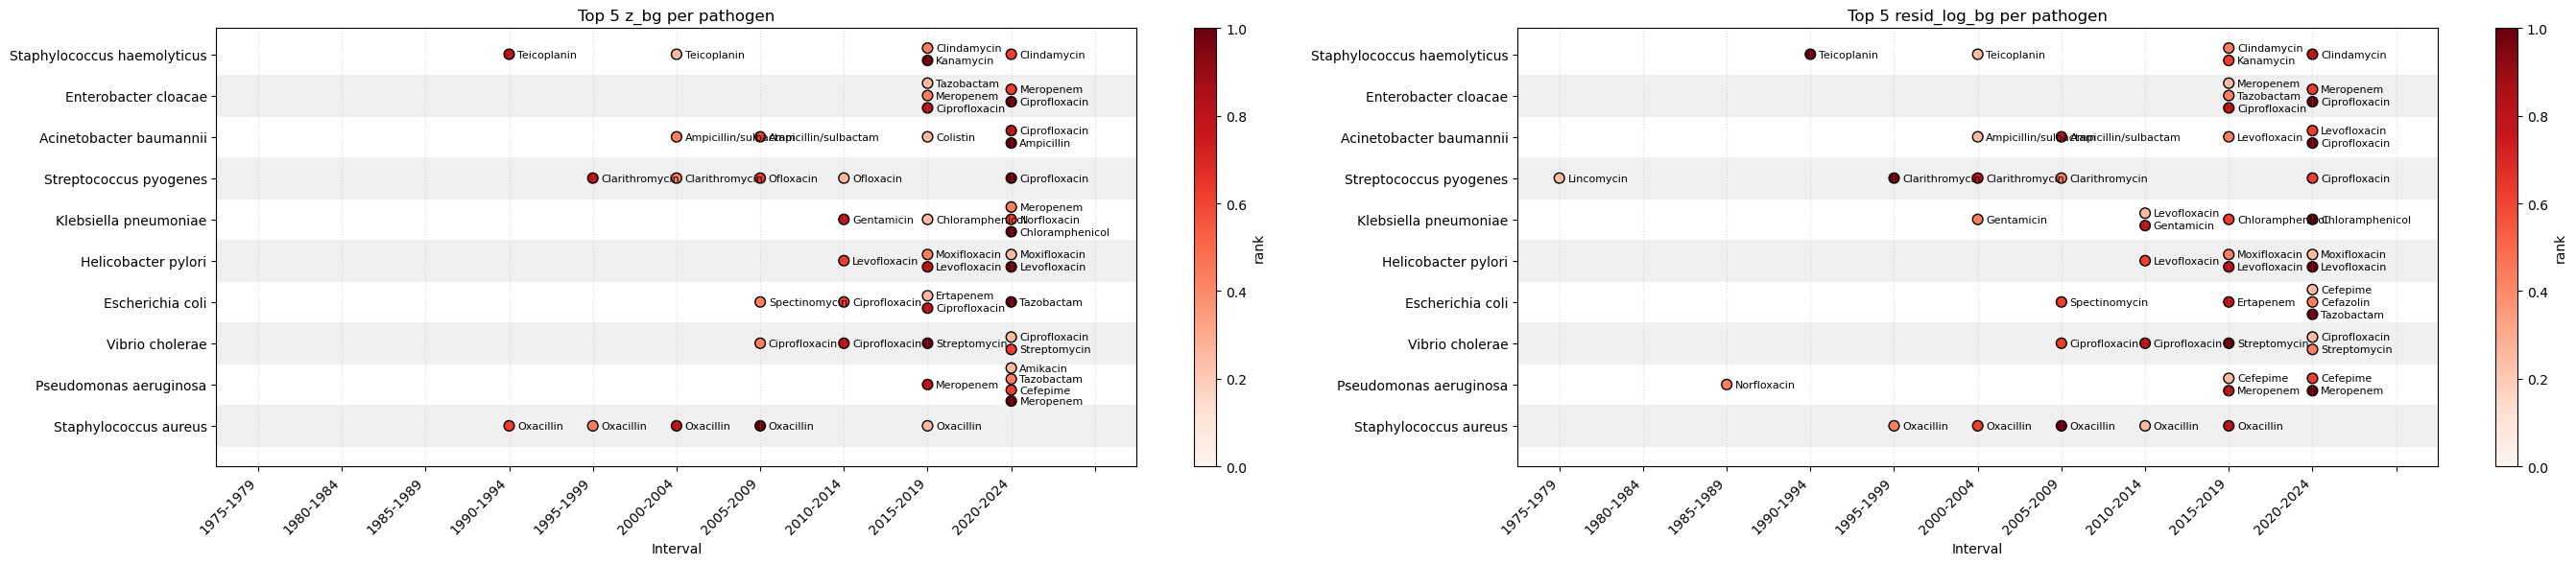

In [28]:
from amr.visualization import plot_top_antibiotic_period_by_pathogen
plot_top_antibiotic_period_by_pathogen(
    norm_df, 
    values=("z_bg","resid_log_bg"), 
    annotate=True, 
    top_k=5, 
    cmap="Reds", 
    color_by="rank", 
    top_k_pathogens=10,
    width_multiplier=1.75)

---